In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/groundwater_nitrate_annual.csv")

df.head()

,Messstellencode,Jahr,Anzahl Messungen,Jahresmittelwert in mg Nitrat pro Liter,Messstellenname,Wasserkörpercode,Wasserkörpername,Probenahmetiefe in m,Länge in Grad (ETRS89),Breite in Grad (ETRS89)
0,BB_25481088,2012,1,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
1,BB_25481088,2013,1,1.07,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
2,BB_25481088,2014,1,0.31,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
3,BB_25481088,2015,2,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
4,BB_25481088,2016,1,0.16,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854


In [2]:
groundwater_summary = (
    df.groupby(["Wasserkörpercode", "Wasserkörpername"])
    .agg(
        mean_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "mean"),
        median_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "median"),
        max_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "max"),
        number_of_stations=("Messstellencode", "nunique"),
        number_of_observations=("Messstellencode", "size")
    )
    .reset_index()
)

groundwater_summary.head()

,Wasserkörpercode,Wasserkörpername,mean_nitrate,median_nitrate,max_nitrate,number_of_stations,number_of_observations
0,DEGB_DEBB_HAV_BP_1,Buckau / Plane,55.580000,52.000,75.00,1,11
1,DEGB_DEBB_HAV_DA_2,Dahme 2,60.220294,0.950,284.50,4,34
2,DEGB_DEBB_HAV_DJ_1,Dosse / Jäglitz,17.583636,5.495,67.00,2,22
3,DEGB_DEBB_HAV_MS_3,Schlepzig,0.207273,0.060,1.45,1,11
4,DEGB_DEBB_HAV_NU_2,Nuthe,0.133333,0.050,0.66,3,33


In [3]:
print("Number of groundwater bodies:", len(groundwater_summary))

print(
    "Groundwater bodies with mean nitrate > 50 mg/L:",
    (groundwater_summary["mean_nitrate"] > 50).sum()
)

print(
    "Groundwater bodies with median nitrate > 50 mg/L:",
    (groundwater_summary["median_nitrate"] > 50).sum()
)

Number of groundwater bodies: 498
Groundwater bodies with mean nitrate > 50 mg/L: 124
Groundwater bodies with median nitrate > 50 mg/L: 114


In [4]:
groundwater_summary.sort_values(
    "mean_nitrate",
    ascending=False
).head(10)

,Wasserkörpercode,Wasserkörpername,mean_nitrate,median_nitrate,max_nitrate,number_of_stations,number_of_observations
456,DEGB_DEST_OT-4,Flechtinger Höhenzug,328.900000,329.30,370.00,1,5
335,DEGB_DENW_286_06,Hauptterrassen des Rheinlandes,250.390909,244.09,304.58,1,11
272,DEGB_DENI_4_2412,Große Aue Lockergestein rechts,185.215455,179.29,230.20,1,11
450,DEGB_DEST_HAV_UH_7,"Burg-Ziesar Fläming, Moränenlandschaft",174.792000,170.00,201.89,1,10
211,DEGB_DEMV_MEL_EO_12_16,Mittelelde,173.888947,128.80,776.32,2,19
16,DEGB_DEBB_ODR_OD_2,Wriezen,164.090909,150.50,208.50,1,11
488,DEGB_DETH_SAL-GW-026_4,Suedliches Thueringer Keuperbecken,156.431818,159.00,169.00,1,11
191,DEGB_DEHE_2510_3105,2510_3105,141.910000,130.00,165.00,1,11
244,DEGB_DENI_38_02,Leda-Jümme Lockergestein rechts,141.035455,139.58,188.33,1,11
182,DEGB_DEHE_2398_3101,2398_3101,138.000000,120.00,220.00,1,10


In [5]:
groundwater_multi_station = (
    groundwater_summary[
        groundwater_summary["number_of_stations"] >= 2
    ]
    .sort_values("mean_nitrate", ascending=False)
)

groundwater_multi_station.head(10)

,Wasserkörpercode,Wasserkörpername,mean_nitrate,median_nitrate,max_nitrate,number_of_stations,number_of_observations
211,DEGB_DEMV_MEL_EO_12_16,Mittelelde,173.888947,128.800,776.32,2,19
434,DEGB_DESN_SE-3-1,Gröditz,136.069474,140.000,165.56,3,19
371,DEGB_DERP_28,"Rhein, RLP, 5",129.207273,162.500,299.50,3,33
368,DEGB_DERP_21,"Rhein, RLP, 7",126.818182,129.250,215.00,2,22
277,DEGB_DENI_4_2505,Hunte Lockergestein links,120.217727,128.225,168.15,2,22
285,DEGB_DENI_928_26,Untere Vechte links,119.079091,83.575,337.12,2,22
324,DEGB_DENW_27_23,Hauptterrassen des Rheinlandes,117.840000,116.070,157.16,2,11
260,DEGB_DENI_4_2106,Obere Aller mesozoisches Festgestein links,105.994375,141.385,204.00,3,32
420,DEGB_DESN_EL-2-4,Jahna,102.269500,101.250,174.99,3,20
417,DEGB_DESN_EL-2-1,Schwarzer Graben,95.149667,82.100,219.64,3,30


In [6]:
print(
    "Groundwater bodies with at least 2 stations:",
    len(groundwater_multi_station)
)

print(
    "Of these, mean nitrate > 50 mg/L:",
    (groundwater_multi_station["mean_nitrate"] > 50).sum()
)

Groundwater bodies with at least 2 stations: 169
Of these, mean nitrate > 50 mg/L: 44


In [7]:
import matplotlib.pyplot as plt

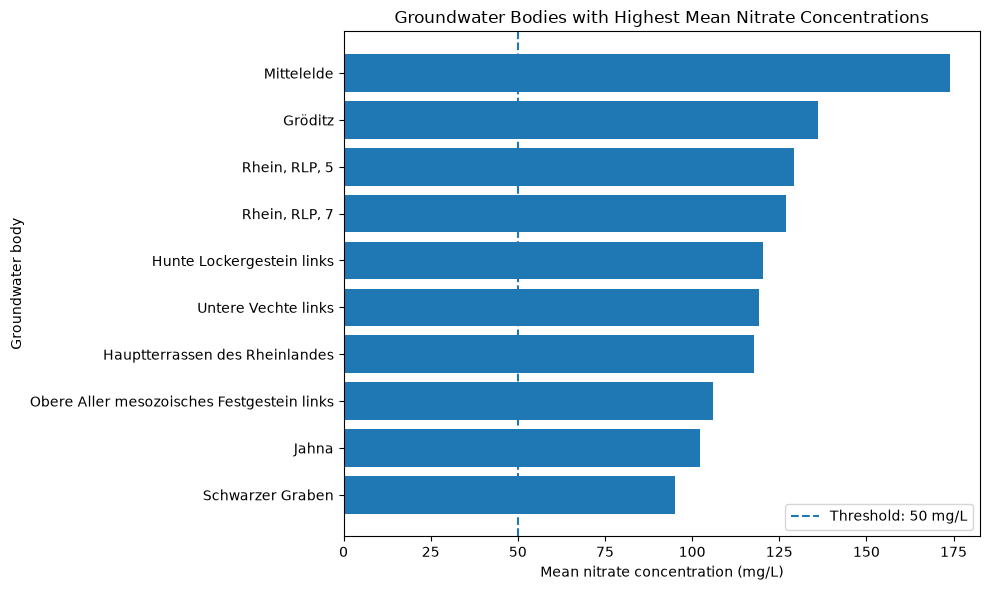

In [8]:
top_groundwater = groundwater_multi_station.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_groundwater["Wasserkörpername"],
    top_groundwater["mean_nitrate"]
)

plt.axvline(
    50,
    linestyle="--",
    label="Threshold: 50 mg/L"
)

plt.xlabel("Mean nitrate concentration (mg/L)")
plt.ylabel("Groundwater body")
plt.title("Groundwater Bodies with Highest Mean Nitrate Concentrations")

plt.legend()
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

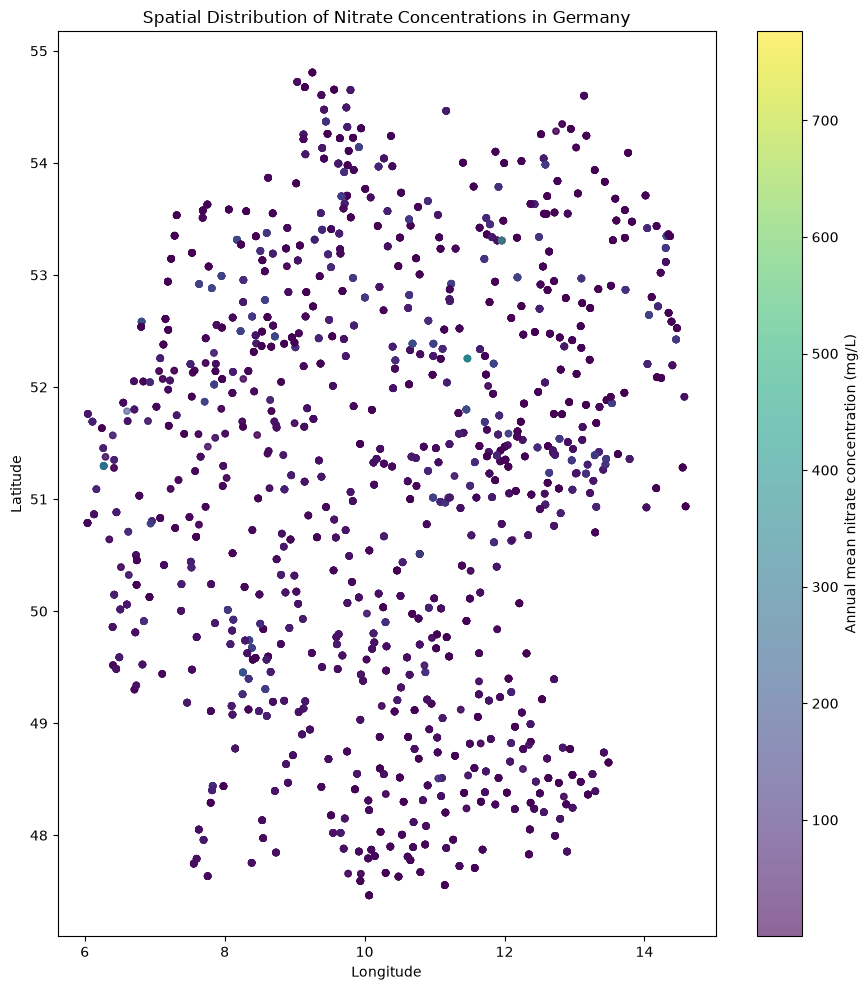

In [9]:
plt.figure(figsize=(9, 10))

scatter = plt.scatter(
    df["Länge in Grad (ETRS89)"],
    df["Breite in Grad (ETRS89)"],
    c=df["Jahresmittelwert in mg Nitrat pro Liter"],
    s=20,
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Annual mean nitrate concentration (mg/L)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Nitrate Concentrations in Germany")

plt.tight_layout()
plt.show()

In [10]:
station_spatial = (
    df.groupby(
        [
            "Messstellencode",
            "Messstellenname",
            "Länge in Grad (ETRS89)",
            "Breite in Grad (ETRS89)"
        ]
    )
    .agg(
        mean_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "mean"),
        max_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "max"),
        years_observed=("Jahr", "count")
    )
    .reset_index()
)

station_spatial.head()

,Messstellencode,Messstellenname,Länge in Grad (ETRS89),Breite in Grad (ETRS89),mean_nitrate,max_nitrate,years_observed
0,BB_25481088,Milow OP,13.821480,53.475854,0.205455,1.07,11
1,BB_25501075,Neuenfeld OP,14.039677,53.417742,79.284545,96.00,11
2,BB_26390030,Krempendorf OP,12.177851,53.332618,0.120000,0.40,11
3,BB_26471092,Buchenhain,13.548628,53.310022,0.314545,1.70,11
4,BB_26480022,Schönermark-Wilhelmshof,13.720348,53.331846,0.134545,0.69,11


In [11]:
station_spatial.shape

(759, 7)

In [12]:
station_spatial["above_50"] = station_spatial["mean_nitrate"] > 50

station_spatial["above_50"].value_counts()

above_50
False    552
True     207
Name: count, dtype: int64

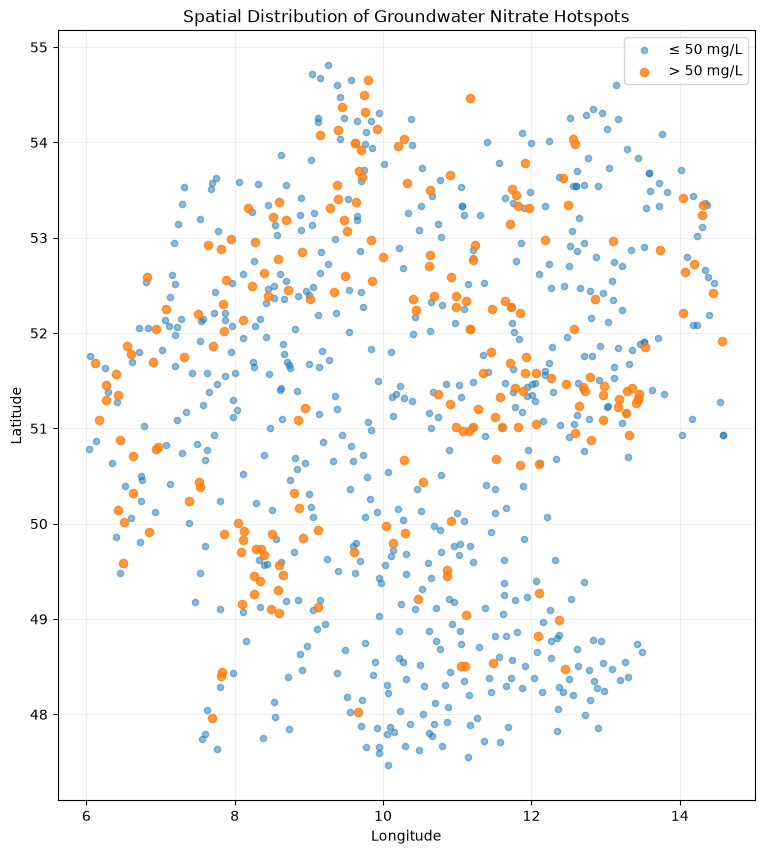

In [13]:
below_50 = station_spatial[station_spatial["above_50"] == False]
above_50 = station_spatial[station_spatial["above_50"] == True]

plt.figure(figsize=(9, 10))

plt.scatter(
    below_50["Länge in Grad (ETRS89)"],
    below_50["Breite in Grad (ETRS89)"],
    s=20,
    alpha=0.5,
    label="≤ 50 mg/L"
)

plt.scatter(
    above_50["Länge in Grad (ETRS89)"],
    above_50["Breite in Grad (ETRS89)"],
    s=35,
    alpha=0.8,
    label="> 50 mg/L"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Groundwater Nitrate Hotspots")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [14]:
top_spatial_hotspots = (
    station_spatial
    .sort_values("mean_nitrate", ascending=False)
    .head(15)
)

top_spatial_hotspots[
    [
        "Messstellencode",
        "Messstellenname",
        "mean_nitrate",
        "max_nitrate",
        "years_observed",
        "Länge in Grad (ETRS89)",
        "Breite in Grad (ETRS89)"
    ]
]

,Messstellencode,Messstellenname,mean_nitrate,max_nitrate,years_observed,Länge in Grad (ETRS89),Breite in Grad (ETRS89)
679,ST_37340030,Wedringen Kanal Süd,328.900000,370.00,5,11.469874,52.254732
346,MV_26370007,Suckow/Parchim,327.415000,776.32,10,11.961610,53.307232
503,NW_080201570,FLOTHEND 200,250.390909,304.58,11,6.271104,51.295740
556,RP_2391181500,"1484 I, Gönnheim",239.302727,299.50,11,8.260970,49.453447
404,NI_40507271,Echtelerfeld I,237.820909,337.12,11,6.812831,52.583403
348,MV_26510010,Hohenholz OP,205.570000,245.43,10,14.315091,53.347762
375,NI_200001392,Nordel I,185.215455,230.20,11,8.717169,52.451703
54,BB_41476054,Kemlitz OP,183.936364,284.50,11,13.535033,51.855877
559,RP_2395164700,"2017, Mettenheim",183.181818,215.00,11,8.352142,49.739840
478,NW_040201491,DINGDEN 59,182.960000,182.96,1,6.602647,51.784627


In [15]:
persistent_spatial_hotspots = (
    station_spatial[
        station_spatial["years_observed"] >= 5
    ]
    .sort_values("mean_nitrate", ascending=False)
)

persistent_spatial_hotspots.head(15)

,Messstellencode,Messstellenname,Länge in Grad (ETRS89),Breite in Grad (ETRS89),mean_nitrate,max_nitrate,years_observed,above_50
679,ST_37340030,Wedringen Kanal Süd,11.469874,52.254732,328.900000,370.00,5,True
346,MV_26370007,Suckow/Parchim,11.961610,53.307232,327.415000,776.32,10,True
503,NW_080201570,FLOTHEND 200,6.271104,51.295740,250.390909,304.58,11,True
556,RP_2391181500,"1484 I, Gönnheim",8.260970,49.453447,239.302727,299.50,11,True
404,NI_40507271,Echtelerfeld I,6.812831,52.583403,237.820909,337.12,11,True
348,MV_26510010,Hohenholz OP,14.315091,53.347762,205.570000,245.43,10,True
375,NI_200001392,Nordel I,8.717169,52.451703,185.215455,230.20,11,True
54,BB_41476054,Kemlitz OP,13.535033,51.855877,183.936364,284.50,11,True
559,RP_2395164700,"2017, Mettenheim",8.352142,49.739840,183.181818,215.00,11,True
682,ST_37375220,Pietzpuhl - Güte,11.844619,52.208782,174.792000,201.89,10,True


In [16]:
station_spatial.to_csv(
    "../data/processed/station_spatial.csv",
    index=False
)

In [17]:
groundwater_summary.to_csv(
    "../data/processed/groundwater_summary.csv",
    index=False
)

In [18]:
persistent_spatial_hotspots.to_csv(
    "../data/processed/persistent_spatial_hotspots.csv",
    index=False
)

In [19]:
import os

os.listdir("../data/processed")

['groundwater_nitrate_annual.csv',
 'groundwater_summary.csv',
 'persistent_spatial_hotspots.csv',
 'station_spatial.csv']